# Air Quality

**Задача:** исследовать показания сенсоров загрязнения воздуха и определить трудности оценки эталонной концентрации угарного газа `CO(GT)` по измерениям того же часа.

**Источник:** [UCI Air Quality](https://archive.ics.uci.edu/dataset/360/air+quality), файл `AirQualityUCI.csv`. CSV должен лежать рядом с ноутбуком. Библиотеки: `pandas`, `matplotlib`, `seaborn`.

## 1. Таблица

Размер, типы, первые строки и сводная статистика. В CSV разделитель `;`, десятичный знак - запятая.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
raw = pd.read_csv("AirQualityUCI.csv", sep=";", decimal=",")
print("Размер исходного CSV:", raw.shape)
print("Строк без даты:", int(raw["Date"].isna().sum()))
print("Полностью пустые столбцы:", raw.columns[raw.isna().all()].tolist())
df = raw.dropna(subset=["Date", "Time"]).drop(columns=["Unnamed: 15", "Unnamed: 16"]).copy()
print("Строк и столбцов с измерениями:", df.shape)
print("Типы:", df.dtypes.value_counts().to_dict())
display(df.head())

Размер исходного CSV: (9471, 17)
Строк без даты: 114
Полностью пустые столбцы: ['Unnamed: 15', 'Unnamed: 16']
Строк и столбцов с измерениями: (9357, 15)
Типы: {dtype('float64'): 13, <StringDtype(storage='python', na_value=nan)>: 2}


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


In [2]:
display(df.describe(include="all").T.round(2))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,9357,391,11/03/2004,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9357,24,18.00.00,390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CO(GT),9357.0,NaN,NaN,NaN,-34.207524,77.65717,-200.0,0.6,1.5,2.6,11.9
PT08.S1(CO),9357.0,NaN,NaN,NaN,1048.990061,329.83271,-200.0,921.0,1053.0,1221.0,2040.0
NMHC(GT),9357.0,NaN,NaN,NaN,-159.090093,139.789093,-200.0,-200.0,-200.0,-200.0,1189.0
C6H6(GT),9357.0,NaN,NaN,NaN,1.865683,41.380206,-200.0,4.0,7.9,13.6,63.7
PT08.S2(NMHC),9357.0,NaN,NaN,NaN,894.595276,342.333252,-200.0,711.0,895.0,1105.0,2214.0
NOx(GT),9357.0,NaN,NaN,NaN,168.616971,257.433866,-200.0,50.0,141.0,284.0,1479.0
PT08.S3(NOx),9357.0,NaN,NaN,NaN,794.990168,321.993552,-200.0,637.0,794.0,960.0,2683.0
NO2(GT),9357.0,NaN,NaN,NaN,58.148873,126.940455,-200.0,53.0,96.0,133.0,340.0


Для исследования получено 9 357 строк и 15 столбцов: дата, время и 13 числовых измерений. В исходном CSV дополнительно находятся 114 полностью пустых строк и два пустых столбца.

## 2. Таргет

`CO(GT)` - эталонная концентрация CO в мг/м³. Значение `-200` в исходном файле обозначает отсутствие измерения, а не реальную концентрацию.

CO(GT) без -200: 7674
CO(GT) = -200: 1683
CO(GT), -200 в % строк: 17.99
count    7674.00
mean        2.15
std         1.45
min         0.10
25%         1.10
50%         1.80
75%         2.90
max        11.90
Name: CO(GT), dtype: float64


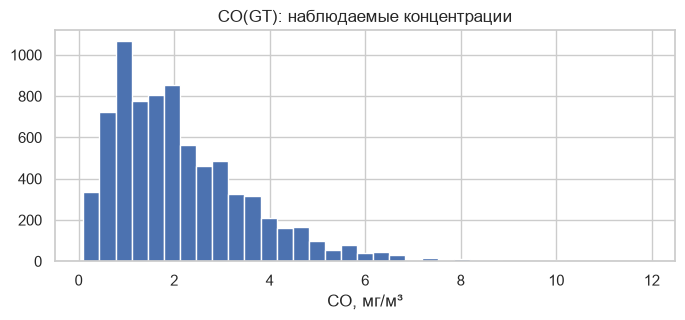

In [3]:
measurements = df.select_dtypes(include="number")
valid = measurements.mask(measurements.eq(-200))
co = valid["CO(GT)"]
print("CO(GT) без -200:", int(co.notna().sum()))
print("CO(GT) = -200:", int(co.isna().sum()))
print("CO(GT), -200 в % строк:", round(100 * co.isna().mean(), 2))
print(co.describe().round(2))
co.hist(bins=35, figsize=(8, 3))
plt.title("CO(GT): наблюдаемые концентрации")
plt.xlabel("CO, мг/м³")
plt.show()

После исключения специального кода для `CO(GT)` остаётся 7 674 наблюдаемых значения; у 1 683 строк таргет отсутствует (17,99%). Наблюдаемые концентрации изменяются от 0,1 до 11,9 мг/м³, медиана - 1,8 мг/м³. Исходная задача - регрессия.

## 3. Пропуски и специальные значения

Проверяются формальные `NaN` после чтения строк с измерениями и специальные значения `-200` во всех 13 числовых столбцах.

In [4]:
flags = measurements.eq(-200)
missing = flags.sum().sort_values(ascending=False)
print("Формальных NaN в таблице измерений:", int(df.isna().sum().sum()))
print("Всего -200 в числовых ячейках:", int(missing.sum()))
print("Доля -200 в числовых ячейках, %:", round(100 * missing.sum() / measurements.size, 2))
print("Строк хотя бы с одним -200:", int(flags.any(axis=1).sum()))
print("Строк без -200:", int((~flags.any(axis=1)).sum()))
display(pd.DataFrame({"-200": missing, "Доля строк, %": (100 * missing / len(df)).round(2)}))

Формальных NaN в таблице измерений: 0
Всего -200 в числовых ячейках: 16701
Доля -200 в числовых ячейках, %: 13.73
Строк хотя бы с одним -200: 8530
Строк без -200: 827


,-200,"Доля строк, %"
NMHC(GT),8443,90.23
CO(GT),1683,17.99
NO2(GT),1642,17.55
NOx(GT),1639,17.52
PT08.S1(CO),366,3.91
PT08.S2(NMHC),366,3.91
C6H6(GT),366,3.91
PT08.S3(NOx),366,3.91
PT08.S4(NO2),366,3.91
PT08.S5(O3),366,3.91


Самая длинная последовательность отсутствующего CO(GT), часов: 173
Наблюдаемых NMHC(GT): 914


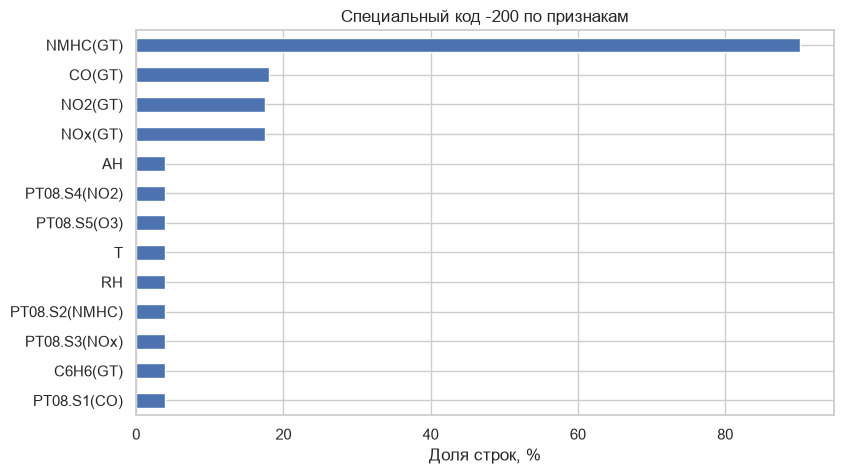

In [5]:
target_missing = flags["CO(GT)"]
runs = target_missing.groupby(target_missing.ne(target_missing.shift()).cumsum()).sum()
print("Самая длинная последовательность отсутствующего CO(GT), часов:", int(runs.max()))
print("Наблюдаемых NMHC(GT):", int(valid["NMHC(GT)"].notna().sum()))
(100 * flags.mean()).sort_values().plot.barh(figsize=(9, 5))
plt.title("Специальный код -200 по признакам")
plt.xlabel("Доля строк, %")
plt.show()

Обозначение `-200` встречается 16 701 раз (13,73% числовых ячеек). Наибольшая доля - у `NMHC(GT)`: 8 443 строки (90,23%). У `CO(GT)` - 17,99%, а у каждого из пяти сенсорных откликов `PT08` - 3,91%. Имеется последовательность из 173 часов без эталонного `CO(GT)`. Пропуски распределены по столбцам неодинаково.

## 4. Временная структура и дубликаты

Проверяется последовательность часовых меток и соответствие ожидаемой временной сетке.

In [6]:
time = pd.to_datetime(df["Date"] + " " + df["Time"].str.replace(".", ":", regex=False),
                      format="%d/%m/%Y %H:%M:%S")
expected = pd.date_range(time.min(), time.max(), freq="h")
print("Первое наблюдение:", time.min())
print("Последнее наблюдение:", time.max())
print("Часов в ожидаемой сетке:", len(expected))
print("Отсутствующих часов:", len(expected.difference(pd.DatetimeIndex(time))))
print("Повторов даты и часа:", int(time.duplicated().sum()))
print("Полных дубликатов строк:", int(df.duplicated().sum()))
print("Временные метки упорядочены:", bool(time.is_monotonic_increasing))

Первое наблюдение: 2004-03-10 18:00:00
Последнее наблюдение: 2005-04-04 14:00:00
Часов в ожидаемой сетке: 9357
Отсутствующих часов: 0
Повторов даты и часа: 0
Полных дубликатов строк: 0
Временные метки упорядочены: True


,Строк,CO наблюдается,"CO отсутствует, %"
Период,,,
2004-03,510,492,3.53
2004-04,720,495,31.25
2004-05,744,592,20.43
2004-06,720,644,10.56
2004-07,744,558,25.00
2004-08,744,477,35.89
2004-09,720,556,22.78
2004-10,744,393,47.18
2004-11,720,679,5.69


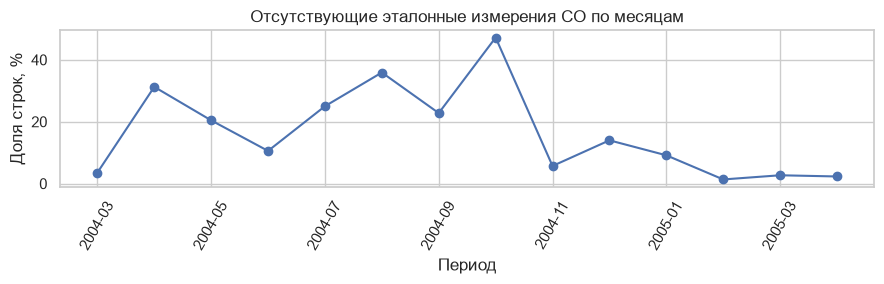

In [7]:
by_period = pd.DataFrame({"Период": time.dt.to_period("M").astype(str),
                          "CO": co, "CO отсутствует": co.isna()})
monthly = by_period.groupby("Период").agg(
    **{"Строк": ("CO", "size"), "CO наблюдается": ("CO", "count"),
       "CO отсутствует, %": ("CO отсутствует", lambda s: round(100 * s.mean(), 2))})
display(monthly)
monthly["CO отсутствует, %"].plot(figsize=(9, 3), marker="o")
plt.title("Отсутствующие эталонные измерения CO по месяцам")
plt.ylabel("Доля строк, %")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

Наблюдения идут по часам с 10.03.2004 18:00 до 04.04.2005 14:00: 9 357 часовых меток без пропусков и повторов. При этом измерения внутри существующих строк могут отсутствовать. Доля отсутствующего `CO(GT)` различается по месяцам.

## 5. Диапазоны, распределения и IQR

Условия проверяются после исключения `-200` из расчётов. Метод IQR применяется только как предварительная проверка выбранных непрерывных величин.

In [8]:
print("Наблюдаемый CO(GT) меньше нуля:", int(co.dropna().lt(0).sum()))
print("RH вне диапазона 0–100:", int((~valid["RH"].dropna().between(0, 100)).sum()))
print("Наблюдаемый T, минимум и максимум:", valid["T"].min(), valid["T"].max())
for col in ["CO(GT)", "PT08.S1(CO)", "NO2(GT)", "T"]:
    s = valid[col].dropna()
    q1, q3 = s.quantile([.25, .75])
    flag = s.lt(q1 - 1.5 * (q3-q1)) | s.gt(q3 + 1.5 * (q3-q1))
    print(col, "IQR-сигналы:", int(flag.sum()),
          f"({100 * flag.mean():.2f}% заполненных строк)",
          "медиана:", round(s.median(), 2))

Наблюдаемый CO(GT) меньше нуля: 0
RH вне диапазона 0–100: 0
Наблюдаемый T, минимум и максимум: -1.9 44.6
CO(GT) IQR-сигналы: 215 (2.80% заполненных строк) медиана: 1.8
PT08.S1(CO) IQR-сигналы: 118 (1.31% заполненных строк) медиана: 1063.0
NO2(GT) IQR-сигналы: 107 (1.39% заполненных строк) медиана: 109.0
T IQR-сигналы: 3 (0.03% заполненных строк) медиана: 17.8


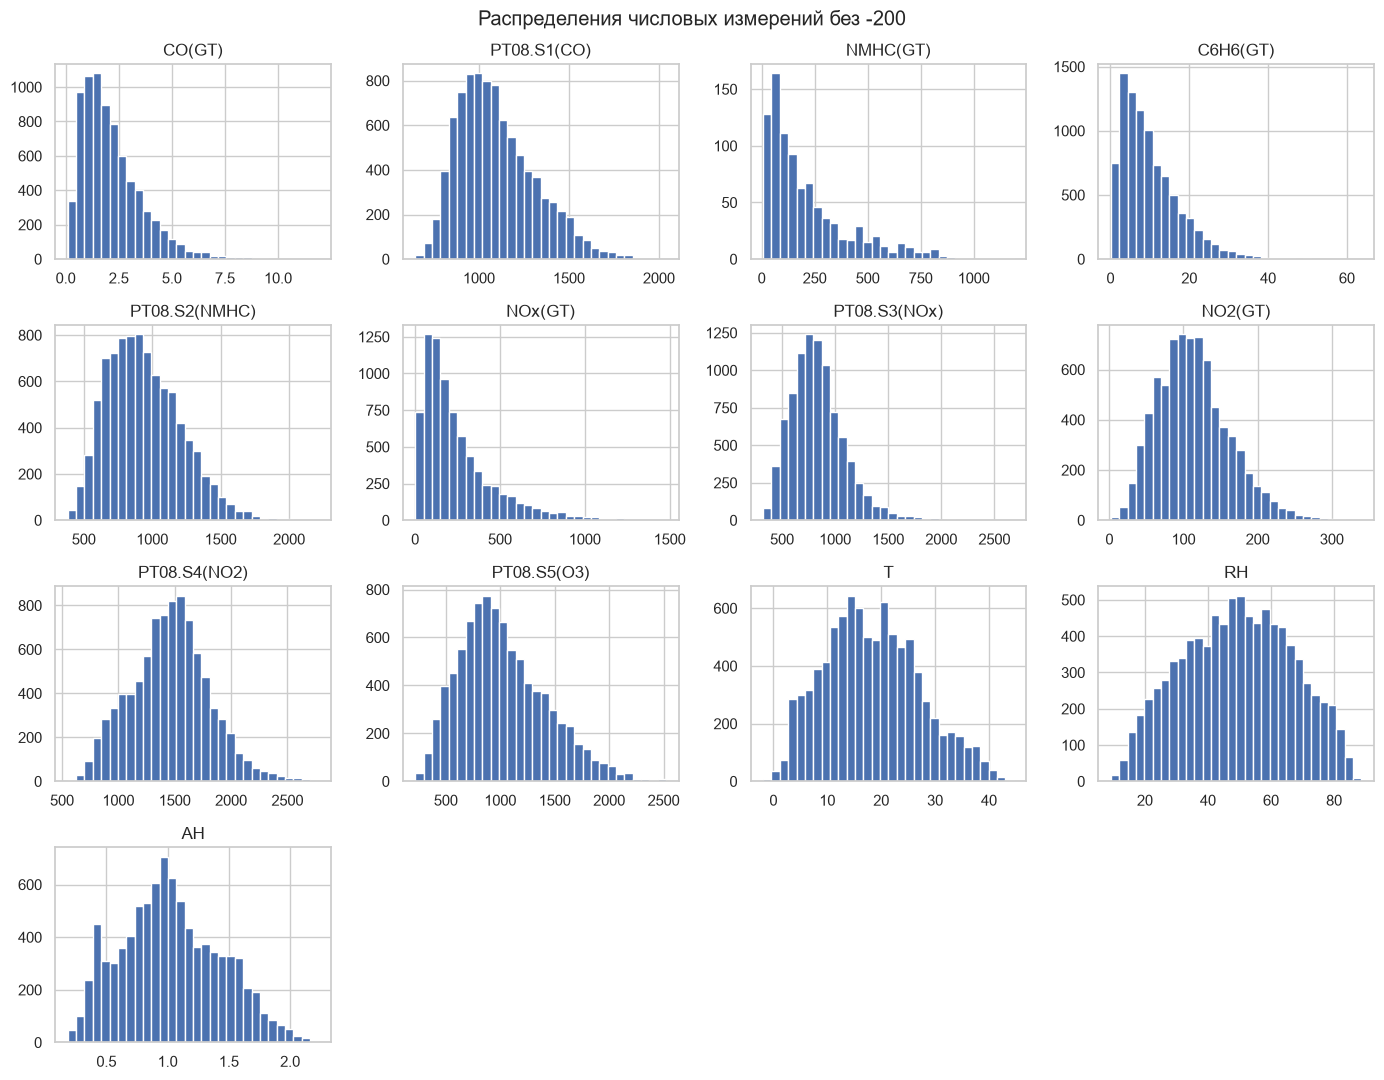

In [9]:
valid.hist(bins=30, figsize=(14, 11), layout=(4, 4))
plt.suptitle("Распределения числовых измерений без -200")
plt.tight_layout()
plt.show()

Нарушений проверенных границ `CO(GT)` и `RH` не обнаружено. Температура `T` изменяется от −1,9 до 44,6 °C. IQR отмечает 215 значений `CO(GT)` (2,80% наблюдаемых), 118 значений `PT08.S1(CO)` (1,31%), 107 значений `NO2(GT)` (1,39%) и 3 значения `T` (0,03%). Признаки имеют разные распределения.

## 6. Связь с календарём

Сравниваются наблюдаемые концентрации `CO(GT)` по часам суток и календарным месяцам. Группы содержат разное количество измерений.

По часам:


,count,mean,median
Час,,,
0,329,1.79,1.60
1,323,1.47,1.30
2,320,1.10,0.90
3,312,0.89,0.70
4,179,0.76,0.60
5,317,0.71,0.60
6,320,0.92,0.90
7,321,1.81,1.50
8,320,2.82,2.85


По месяцам:


,count,mean,median
Месяц,,,
1,676,2.14,1.70
2,663,2.10,1.80
3,1216,2.14,1.90
4,580,2.14,1.80
5,592,1.94,1.80
6,644,1.90,1.70
7,558,1.78,1.60
8,477,1.28,1.20
9,556,2.16,1.85


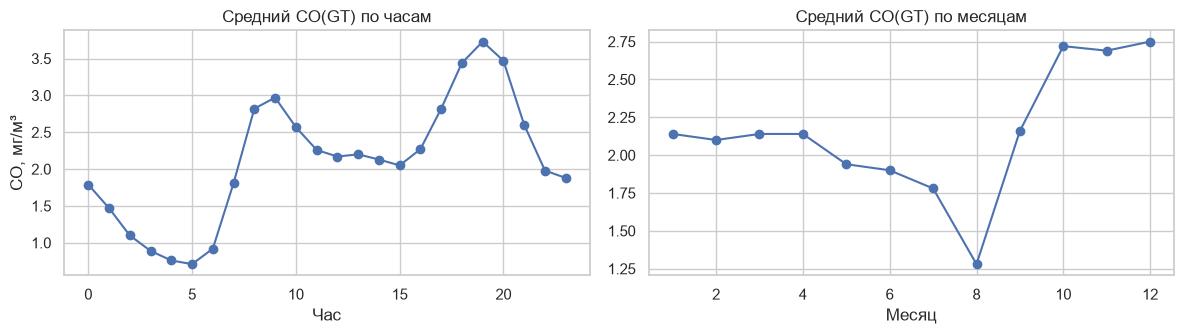

In [10]:
calendar = pd.DataFrame({"CO": co, "Час": time.dt.hour, "Месяц": time.dt.month})
hours = calendar.groupby("Час")["CO"].agg(["count", "mean", "median"]).round(2)
months = calendar.groupby("Месяц")["CO"].agg(["count", "mean", "median"]).round(2)
print("По часам:")
display(hours)
print("По месяцам:")
display(months)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
hours["mean"].plot(ax=axes[0], marker="o", title="Средний CO(GT) по часам")
months["mean"].plot(ax=axes[1], marker="o", title="Средний CO(GT) по месяцам")
axes[0].set_ylabel("CO, мг/м³")
plt.tight_layout()
plt.show()

Средняя концентрация `CO(GT)` минимальна в 05:00 (0,71 мг/м³), максимальна в 19:00 (3,73 мг/м³). По месяцам минимум в августе (1,28), максимум в декабре (2,75). Различия описывают наблюдаемые группы, но не отделяют сезонность от неполноты измерений и изменений условий наблюдения.

## 7. Корреляции и связь с таргетом

Корреляции рассчитаны только по совместно наблюдаемым значениям. Для `CO(GT)` отдельно сравниваются сенсорные и эталонные измерения.

Корреляции с CO(GT):


CO(GT)           1.000
C6H6(GT)         0.931
PT08.S2(NMHC)    0.916
NMHC(GT)         0.890
PT08.S1(CO)      0.879
PT08.S5(O3)      0.854
NOx(GT)          0.795
NO2(GT)          0.683
PT08.S4(NO2)     0.631
RH               0.049
AH               0.049
T                0.022
PT08.S3(NOx)    -0.703
Name: r с CO(GT), dtype: float64

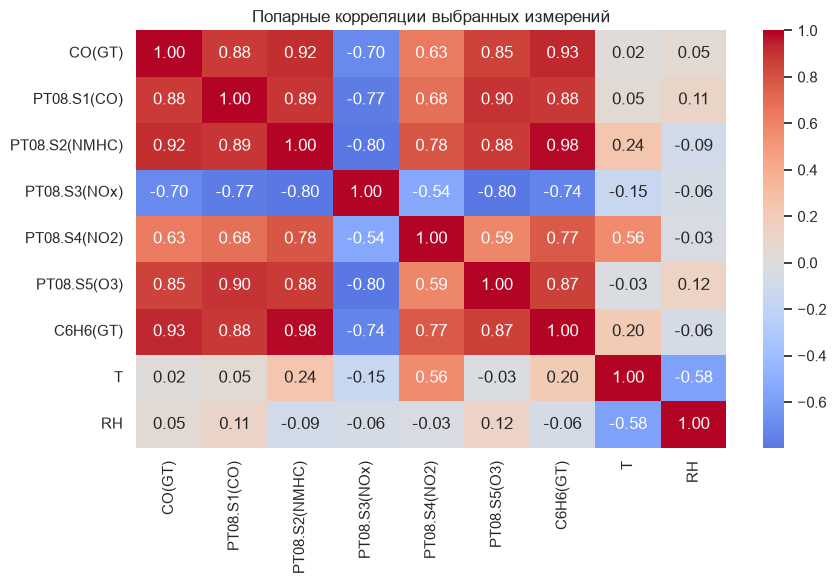

In [11]:
corr_co = valid.corr()["CO(GT)"].sort_values(ascending=False)
print("Корреляции с CO(GT):")
display(corr_co.round(3).rename("r с CO(GT)"))
cols = ["CO(GT)", "PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)",
        "PT08.S4(NO2)", "PT08.S5(O3)", "C6H6(GT)", "T", "RH"]
plt.figure(figsize=(9, 6))
sns.heatmap(valid[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Попарные корреляции выбранных измерений")
plt.tight_layout()
plt.show()

Строк для сравнения четырёх показателей: 7344


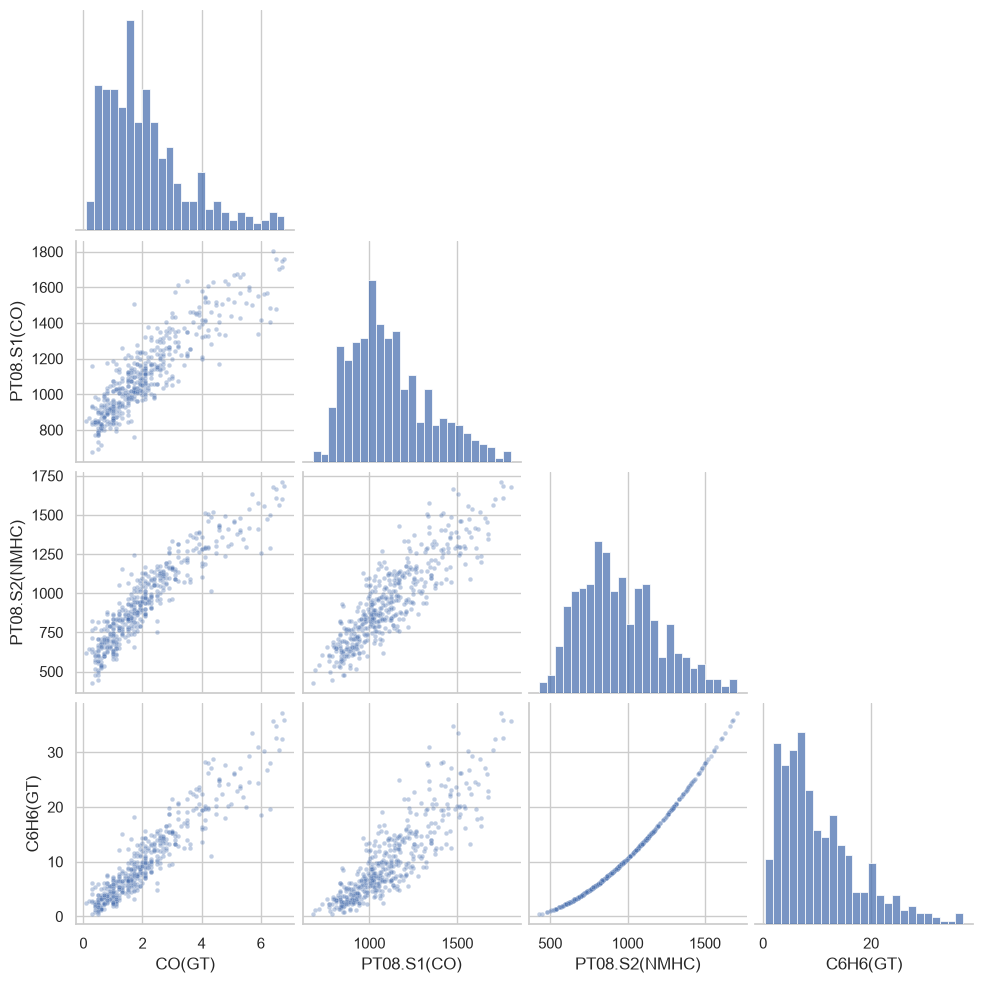

In [12]:
shown = valid[["CO(GT)", "PT08.S1(CO)", "PT08.S2(NMHC)", "C6H6(GT)"]].dropna()
print("Строк для сравнения четырёх показателей:", len(shown))
sample = shown.sample(n=450, random_state=42)
sns.pairplot(sample, corner=True, plot_kws={"alpha": .35, "s": 11},
             diag_kws={"bins": 25, "color": "#4C72B0"})
plt.show()

У `CO(GT)` высокая положительная корреляция с `C6H6(GT)` (≈0,931), `PT08.S2(NMHC)` (≈0,916) и `PT08.S1(CO)` (≈0,879). `C6H6(GT)` - также эталонное измерение, поэтому его доступность в момент применения модели требует отдельного подтверждения. Высокая корреляция не означает, что признаки доступны при прогнозе.

## 8. Проверка зависимости от периода

Раздельно рассматривается связь `CO(GT)` с `PT08.S1(CO)` в двух временных отрезках. Это проверка устойчивости статистической связи, а не доказательство дрейфа датчика.

In [13]:
period = pd.Series(time.ge(pd.Timestamp("2004-10-01")), index=df.index)
for name, mask in [("До 01.10.2004", ~period), ("С 01.10.2004", period)]:
    part = valid.loc[mask, ["CO(GT)", "PT08.S1(CO)"]].dropna()
    print(name, "наблюдений:", len(part),
          "корреляция:", round(part["CO(GT)"].corr(part["PT08.S1(CO)"]), 3))

До 01.10.2004 наблюдений: 3700 корреляция: 0.896
С 01.10.2004 наблюдений: 3644 корреляция: 0.867


Связь `CO(GT)` и `PT08.S1(CO)` рассчитана по отдельным временным отрезкам; различие коэффициентов требует проверки на будущих периодах. По одному этому сравнению дрейф датчиков не устанавливается.

## 9. Выводы и эталон для агента

1. **Цель:** `CO(GT)`, оценка эталонной концентрации угарного газа. Постановка - регрессия.
2. **Пропуски:** распознавать `-200` как специальное обозначение, у `CO(GT)` часть строк не имеет таргета.
3. **Качество данных:** учитывать 114 пустых строк в исходном файле и два пустых столбца.
4. **Признаки:** отдельные эталонные концентрации `(GT)` могут быть недоступны в реальном применении; проверять доступность сенсоров и метеоданных.
5. **Выбросы:** не удалять высокие концентрации по одному правилу IQR.
6. **Время:** использовать хронологическое разбиение для проверки переноса на последующие периоды.
7. **Метрика:** MAE или RMSE в мг/м³ с учётом цели применения.
8. **Устойчивость:** сравнивать качество на разных периодах, авторы UCI отмечают возможный дрейф сенсоров.